In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

models = ["decision_tree", "random_forest", "xgboost", "stacking"]
A = pd.read_csv("results_final_E1/full_feature_results_E1.csv").set_index("model").loc[models]
B = pd.read_csv("results_final_E2/full_feature_results_E2.csv").set_index("model").loc[models]

for d in (A, B):
    d["f1"] = 2 * d.tp / (2 * d.tp + d.fp + d.fn)

/var/folders/qy/2pcb_l_n5tb3h713pxqwm2zm0000gn/T/ipykernel_26478/1130745242.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=datasets.values(), x=datasets.keys(), palette="Blues")


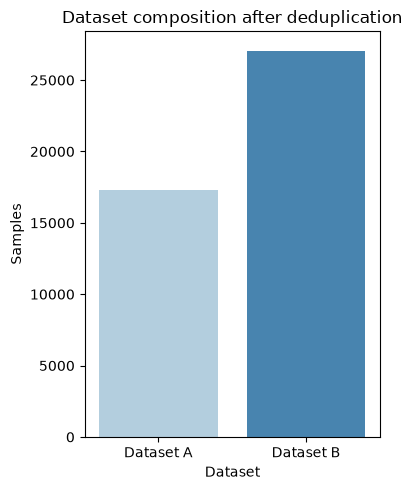

17269

In [2]:
D1 = pd.read_csv("DA_features/features.csv")
D2 = pd.read_csv("DB_features/features.csv")
datasets = {"Dataset A": len(D1),
            "Dataset B": len(D2)}

plt.figure(figsize=(4, 5))
sns.barplot(y=datasets.values(), x=datasets.keys(), palette="Blues")
plt.title("Dataset composition after deduplication")
plt.xlabel("Dataset")
plt.ylabel("Samples")
plt.tight_layout()
plt.show()
len(D1)

In [3]:
# Professional style palette & configurations
LIGHT_SLATE = "#B8BFD6"  
IID_SLATE   = "#53607A"  
DEEP_NAVY   = "#19335A"  
SKY_BLUE    = "#8FC8EB"  
ROYAL_BLUE  = "#4675C0"  
INK         = "#2B2F36"

MODEL_COLORS = {
    "decision_tree": LIGHT_SLATE, 
    "random_forest": IID_SLATE, 
    "xgboost": ROYAL_BLUE, 
    "stacking": DEEP_NAVY
}

MODEL_LABELS = {
    "decision_tree": "Decision Tree", 
    "random_forest": "Random Forest",
    "xgboost": "XGBoost", 
    "stacking": "Stacking"
}

plt.rcParams.update({
    "figure.dpi": 300,
    "font.family": "sans-serif", 
    "font.size": 10,
    "text.color": INK, 
    "axes.labelcolor": INK, 
    "axes.edgecolor": "#9AA3AE",
    "xtick.color": INK, 
    "ytick.color": INK,
    "axes.spines.top": False, 
    "axes.spines.right": False,
    "axes.titlesize": 11, 
    "axes.titleweight": "semibold", 
    "axes.titlepad": 12,
    "axes.grid": True, 
    "grid.color": "#E3E7EC", 
    "grid.linewidth": 0.8,
    "axes.axisbelow": True, 
    "legend.frameon": False,
})

#### Confusion matrices for datasets A and B for different model

findfont: Failed to find font weight semibold, now using 700.


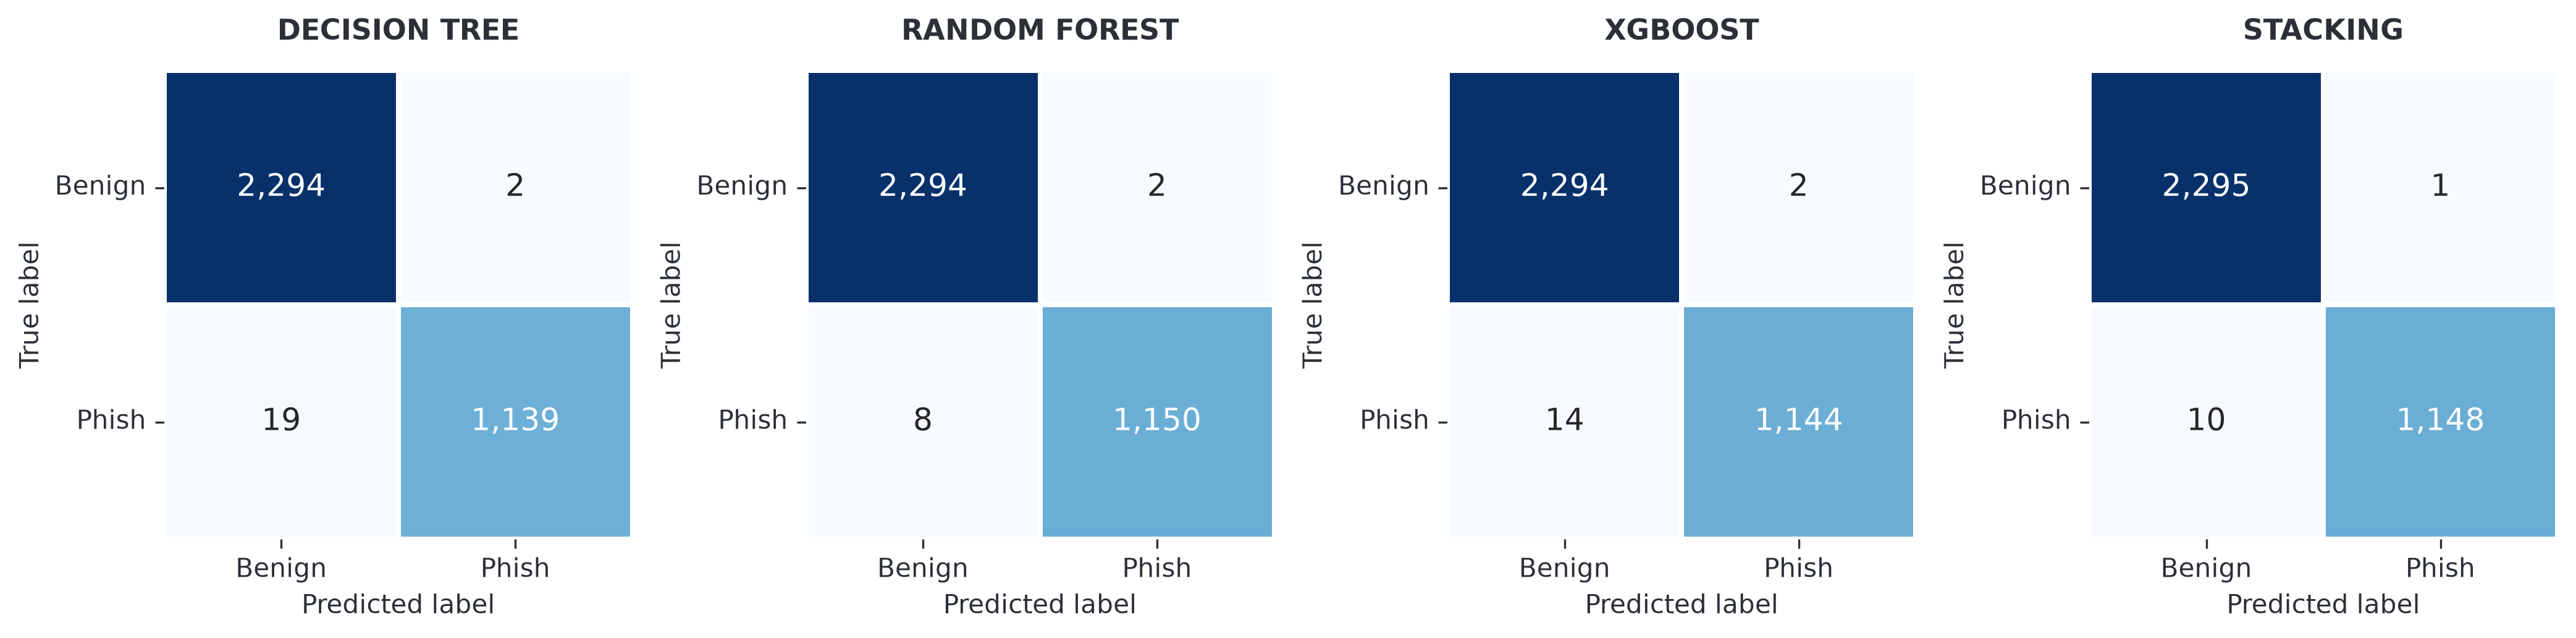

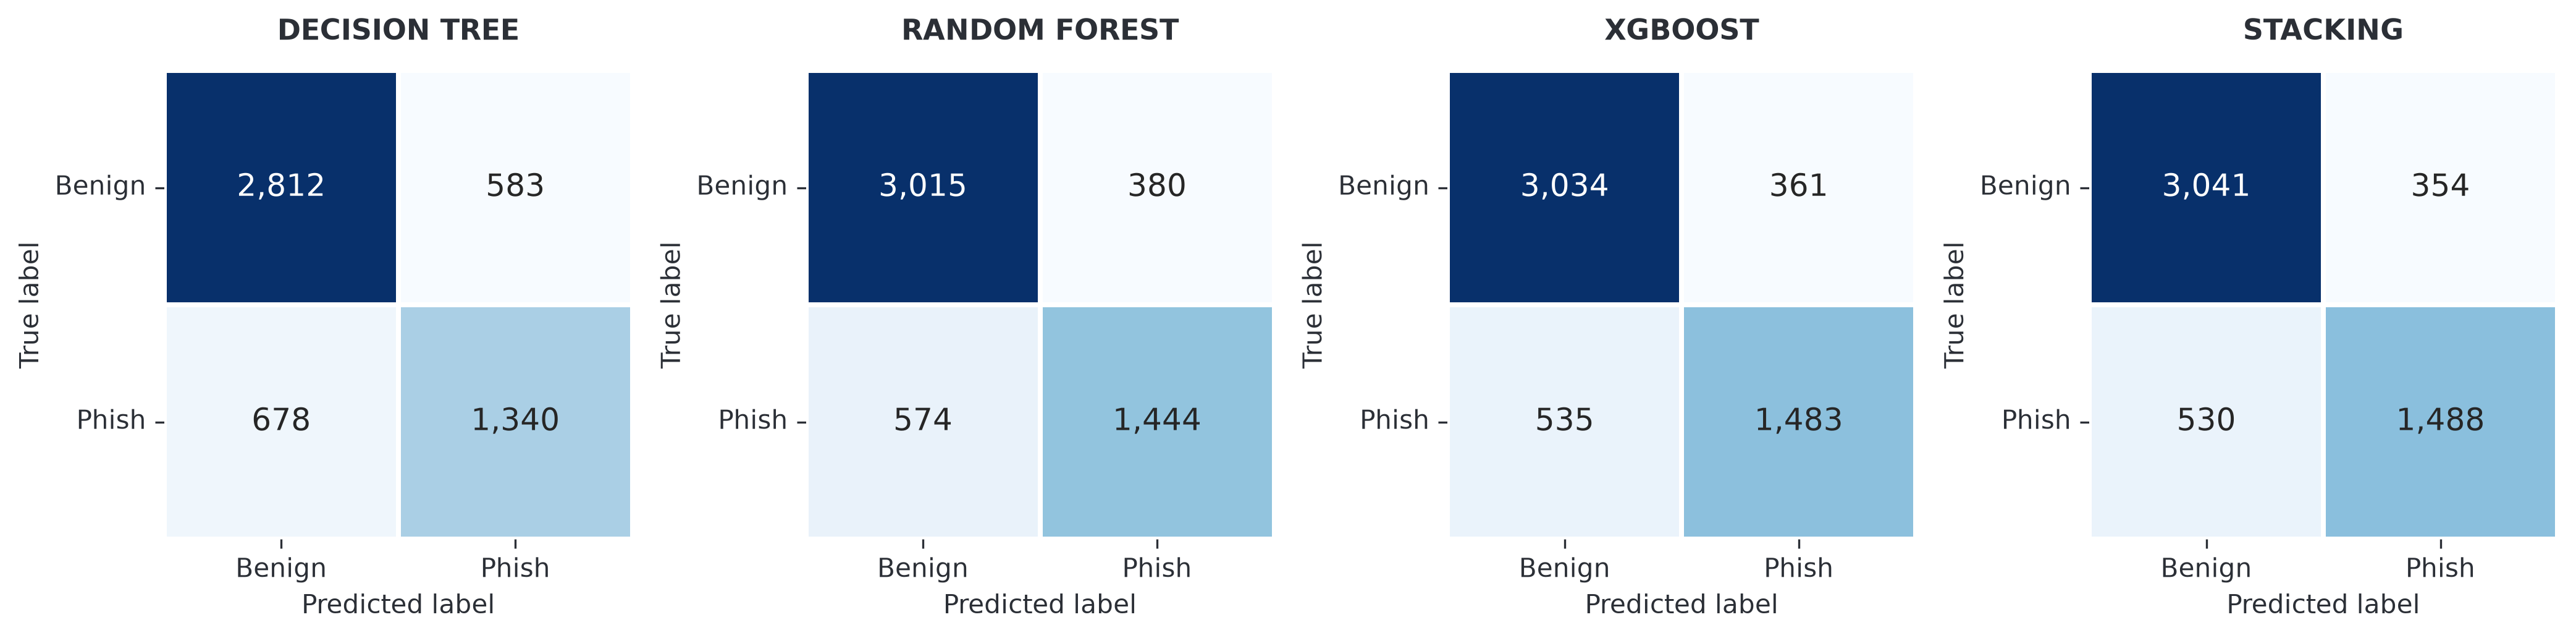

In [4]:
plt.rcParams['figure.dpi'] = 300

for name, d in [("A", A), ("B", B)]:
    fig, axes = plt.subplots(1, len(models), figsize=(14, 4))
    axes = np.atleast_1d(axes)  # Ensures axes is always indexable, even if len(models) == 1
    
    for col, m in enumerate(models):
        cm = [[d.loc[m, "tn"], d.loc[m, "fp"]], [d.loc[m, "fn"], d.loc[m, "tp"]]]
        
        sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, square=True,
                    linewidths=1.5, linecolor="white", annot_kws={"size": 12},
                    xticklabels=["Benign", "Phish"], yticklabels=["Benign", "Phish"], 
                    ax=axes[col])
        
        axes[col].grid(False)
        axes[col].tick_params(axis="y", labelrotation=0)
        axes[col].set_xlabel("Predicted label")
        axes[col].set_ylabel("True label")
        axes[col].set_title(f"{(MODEL_LABELS.get(m, m)).upper()}")

    #fig.suptitle(f"Confusion Matrices for Dataset {name}", fontsize=14, y=1.00)
    plt.tight_layout()
    plt.show()

#### Ablation study

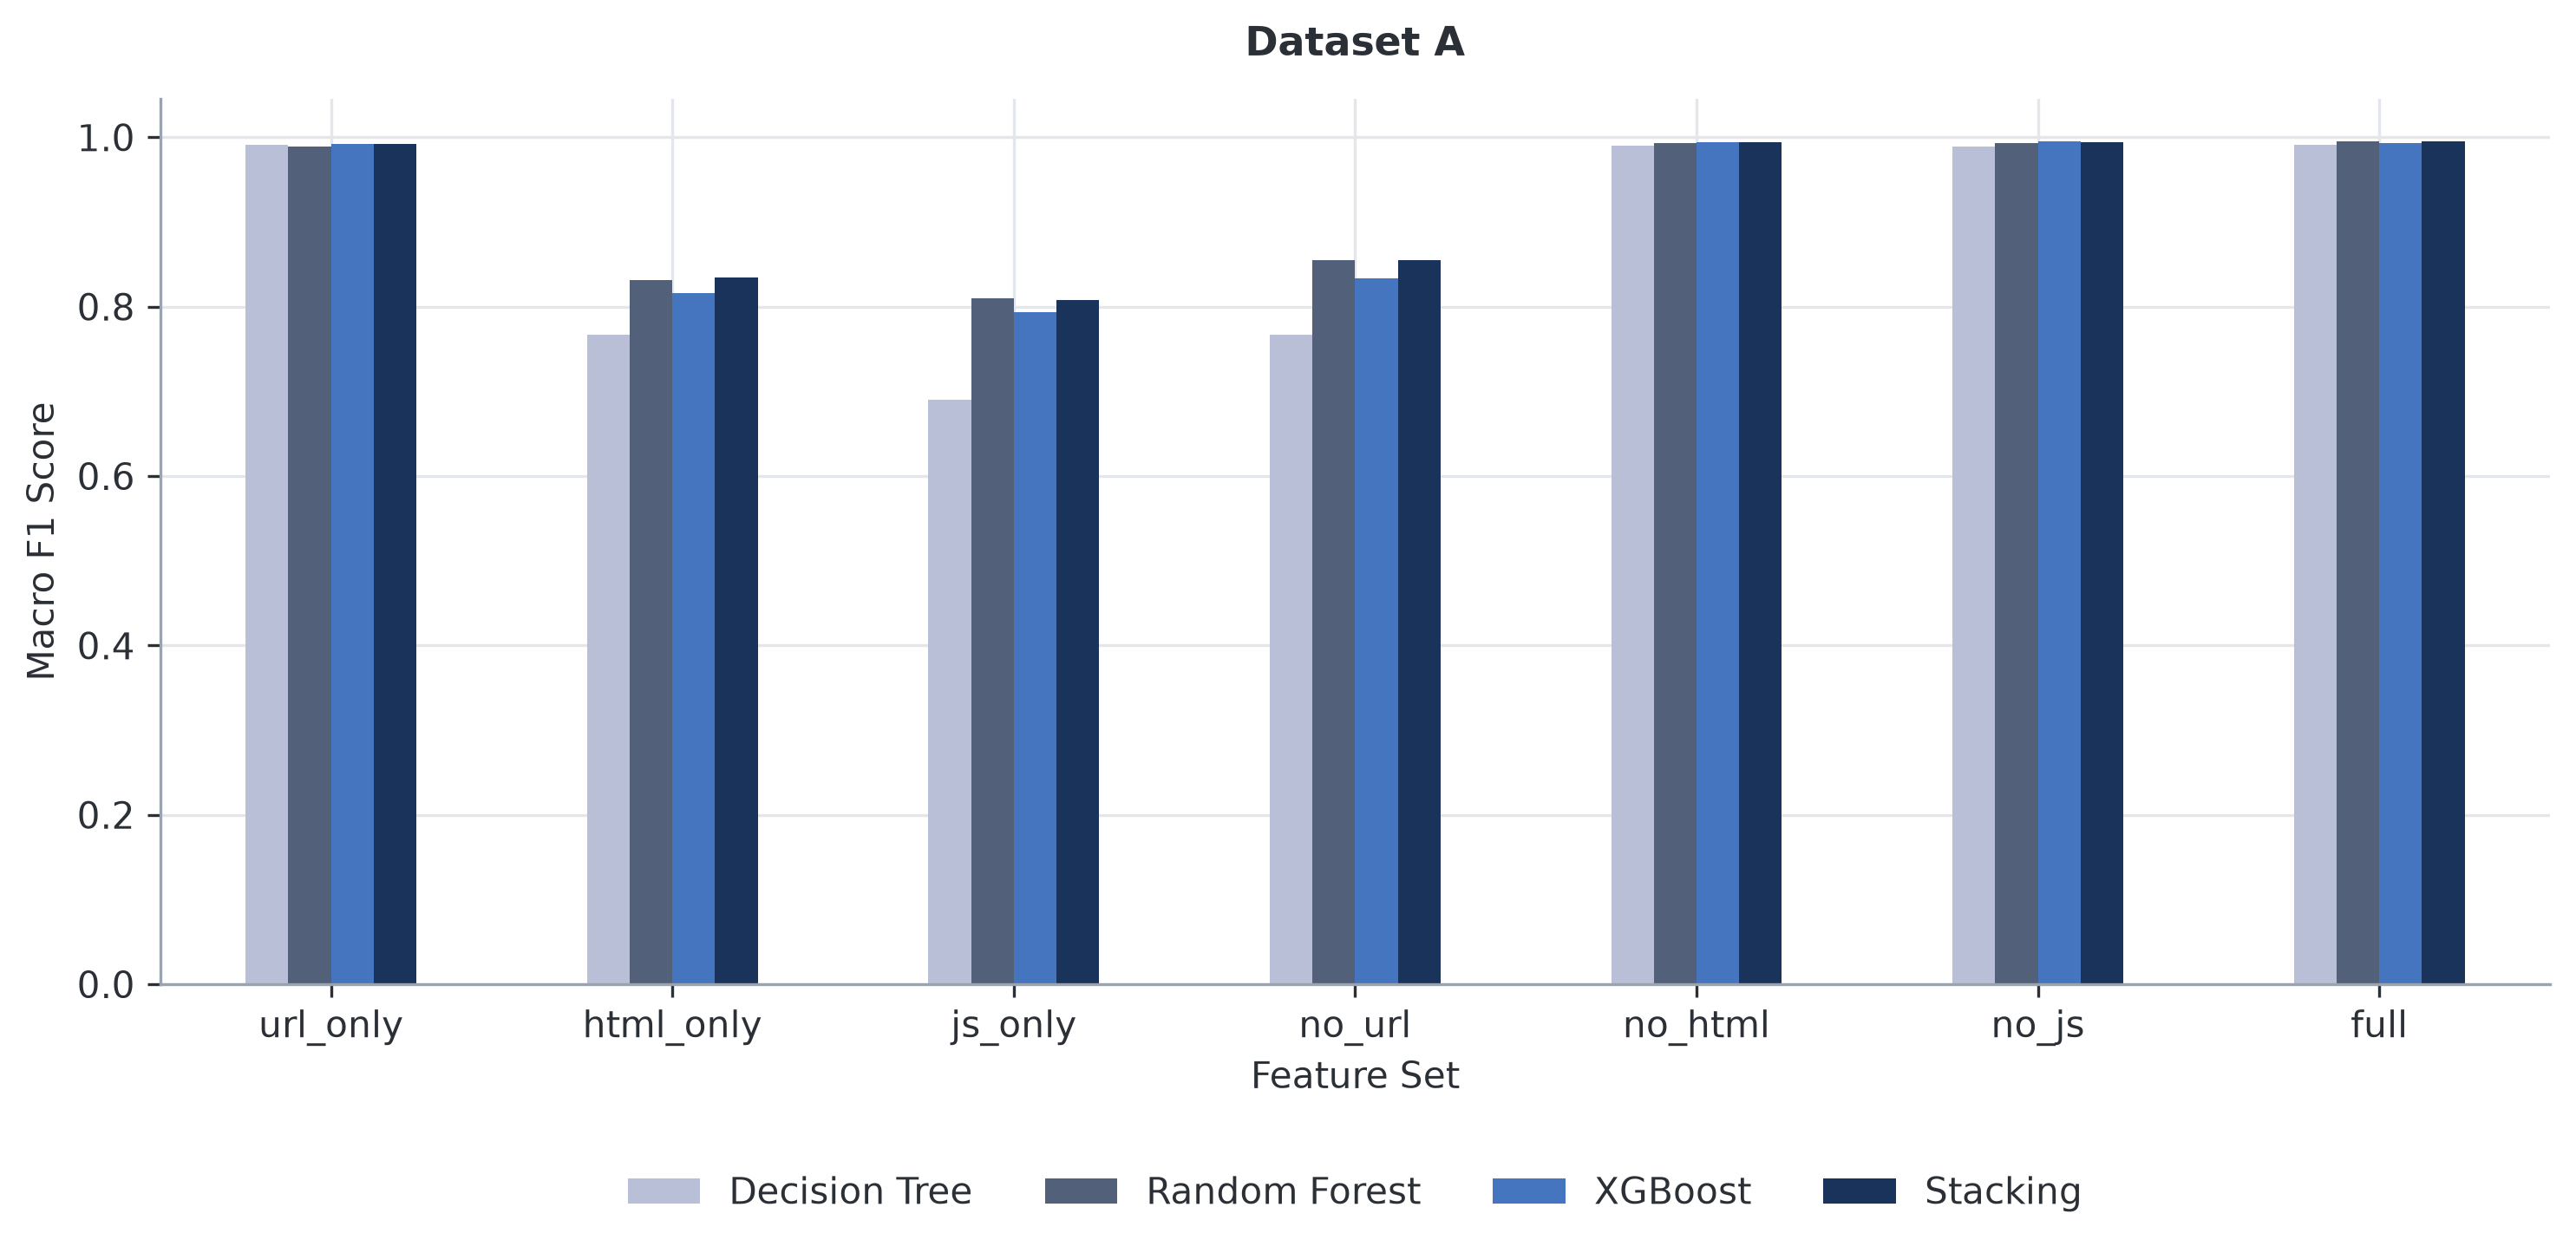

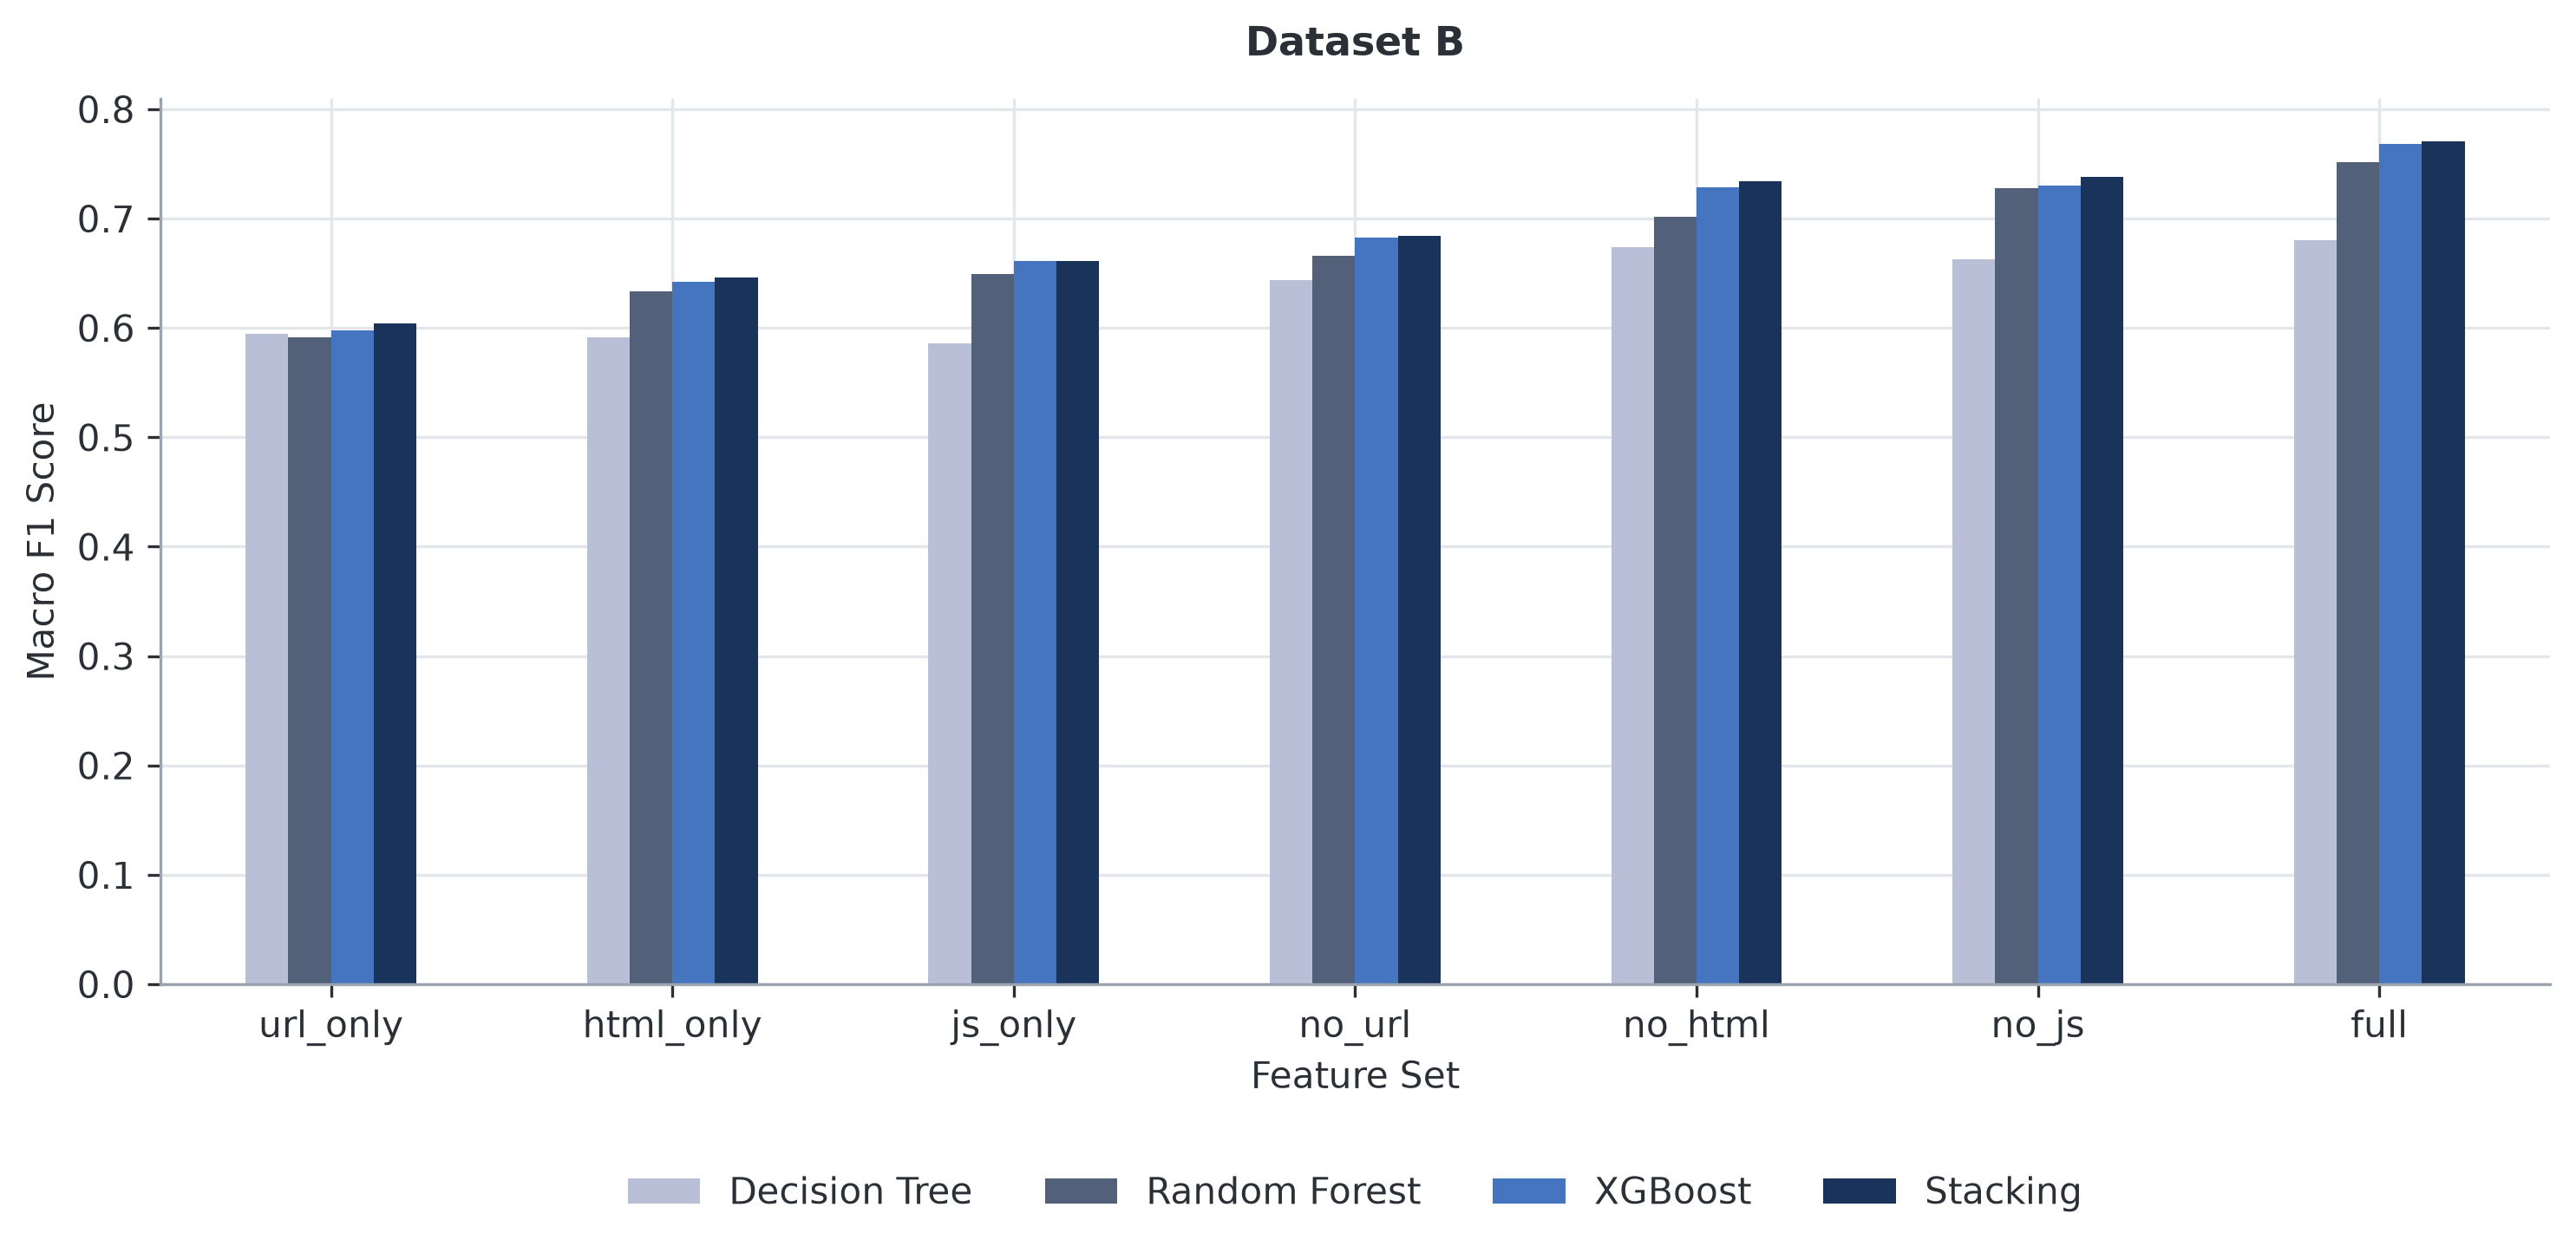

In [5]:
plt.rcParams['figure.dpi'] = 300

datasets = [
    ("A", "results_final_E1/ablation_results_E1.csv", A),
    ("B", "results_final_E2/ablation_results_E2.csv", B)
]

for name, path, full in datasets:
    # Slightly taller figure (5 inches) to accommodate the legend underneath
    fig, ax = plt.subplots(figsize=(10, 5))
    
    abl = pd.read_csv(path)
    abl["f1"] = 2 * abl.tp / (2 * abl.tp + abl.fp + abl.fn)
    
    table = abl.pivot(index="feature_set", columns="model", values="f1")[models]
    table.loc["full"] = full["f1"]
    
    # Map model keys to their designated custom colors
    plot_colors = [MODEL_COLORS.get(m, LIGHT_SLATE) for m in models]
    
    # Rename columns to clean labels for the legend
    table = table.rename(columns=MODEL_LABELS)
    
    subset = table.loc[["url_only", "html_only", "js_only", "no_url", "no_html", "no_js", "full"]]
    subset.plot.bar(ax=ax, title=f"Dataset {name}", color=plot_colors)
    
    ax.set_ylabel("Macro F1 Score")
    ax.set_xlabel("Feature Set")
    plt.xticks(rotation=0)
    
    # Position the legend cleanly underneath the plot area
    ax.legend(
        loc="upper center", 
        bbox_to_anchor=(0.5, -0.18), 
        ncol=len(models),
        frameon=False
    )
    
    plt.tight_layout()
    plt.show()

#### Cost vs Performance

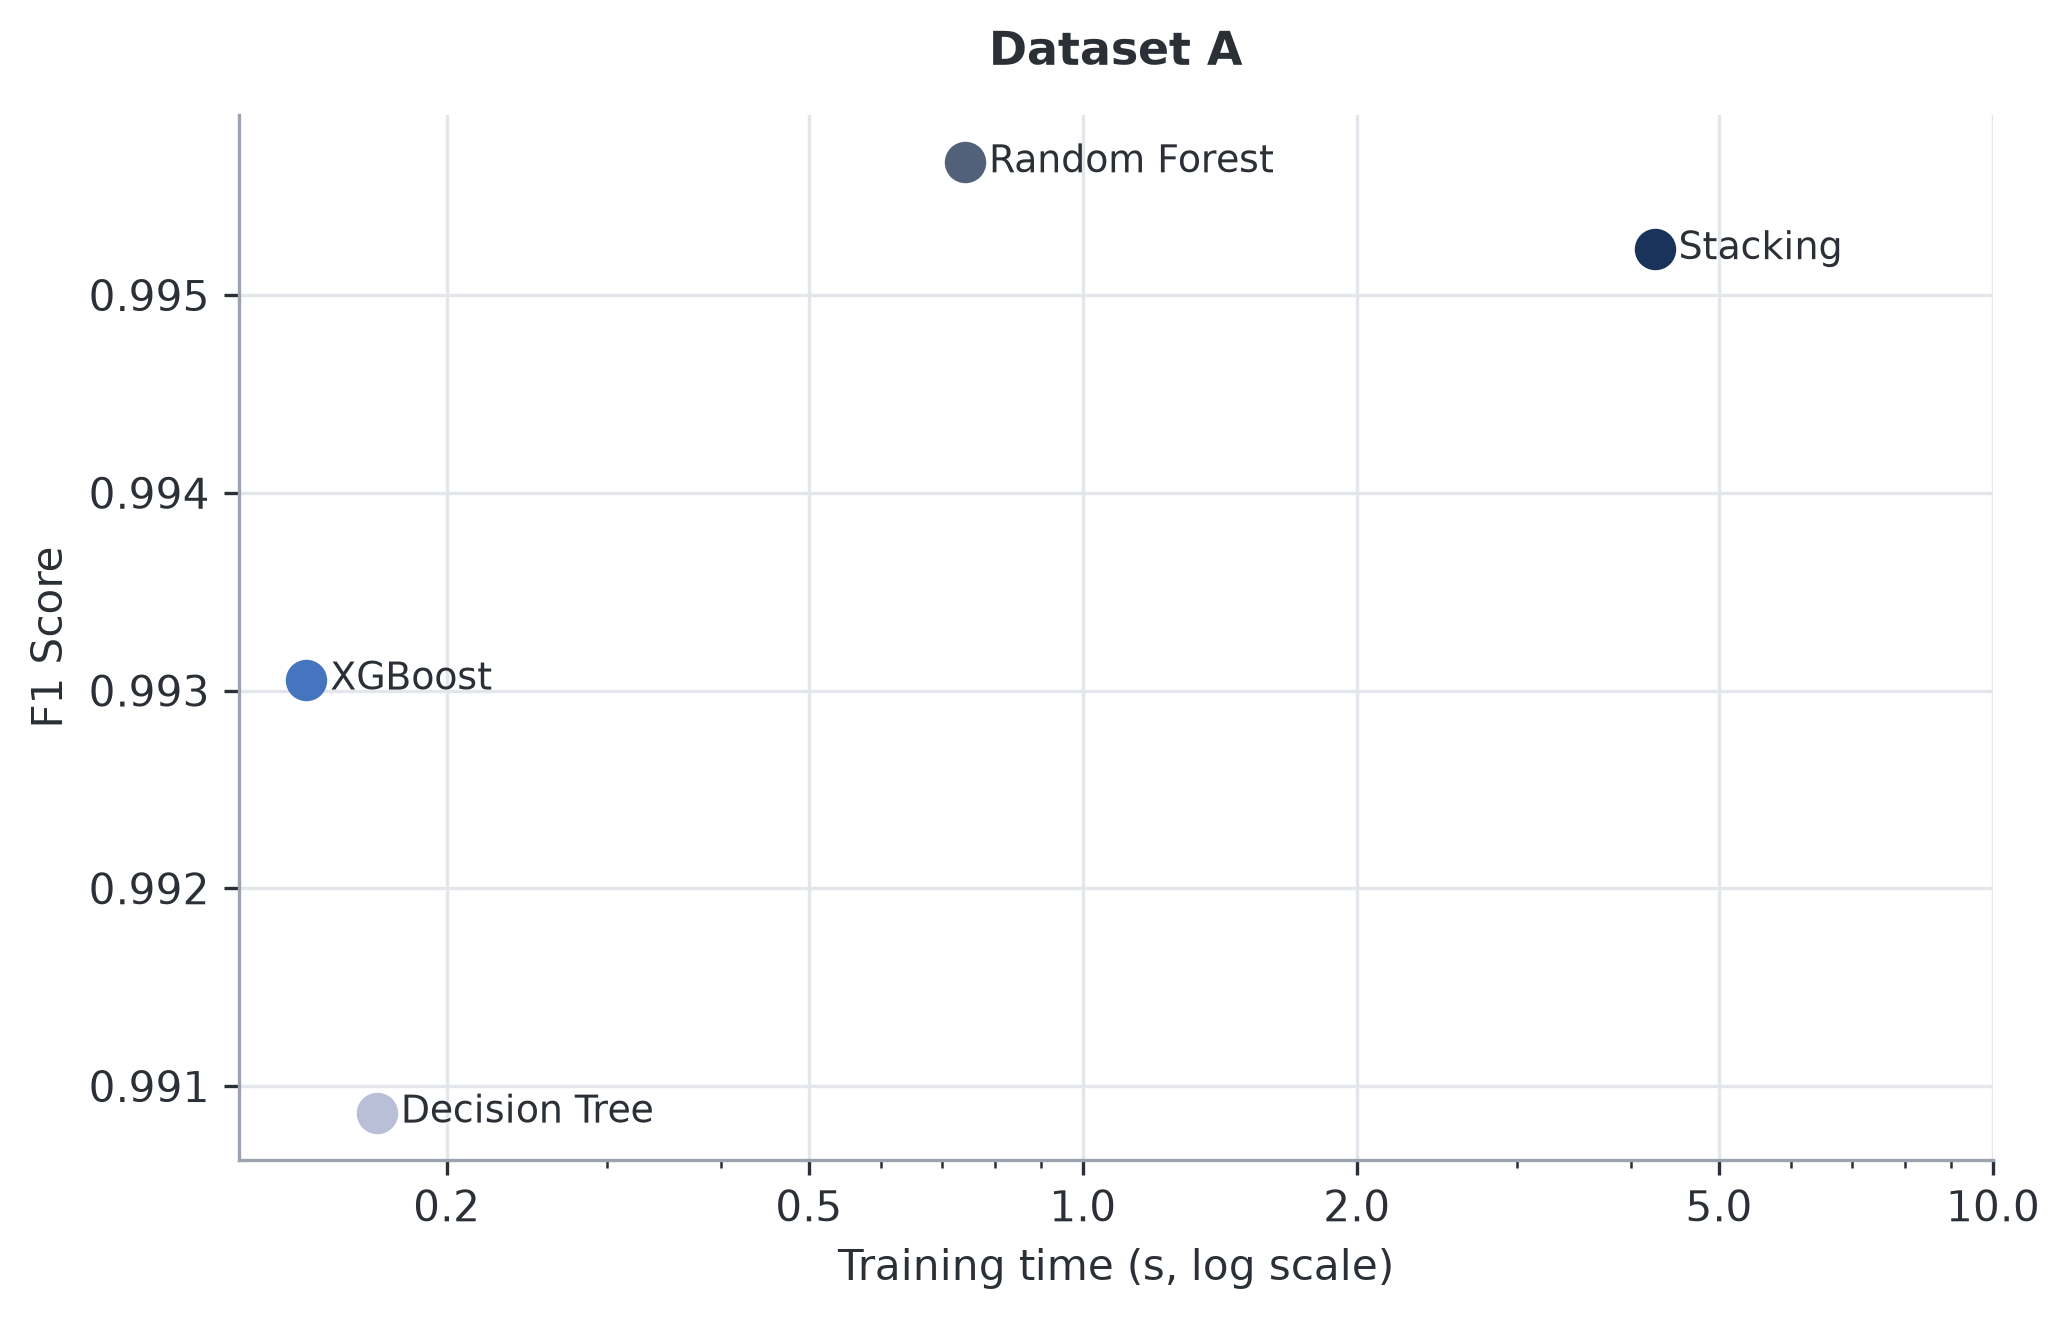

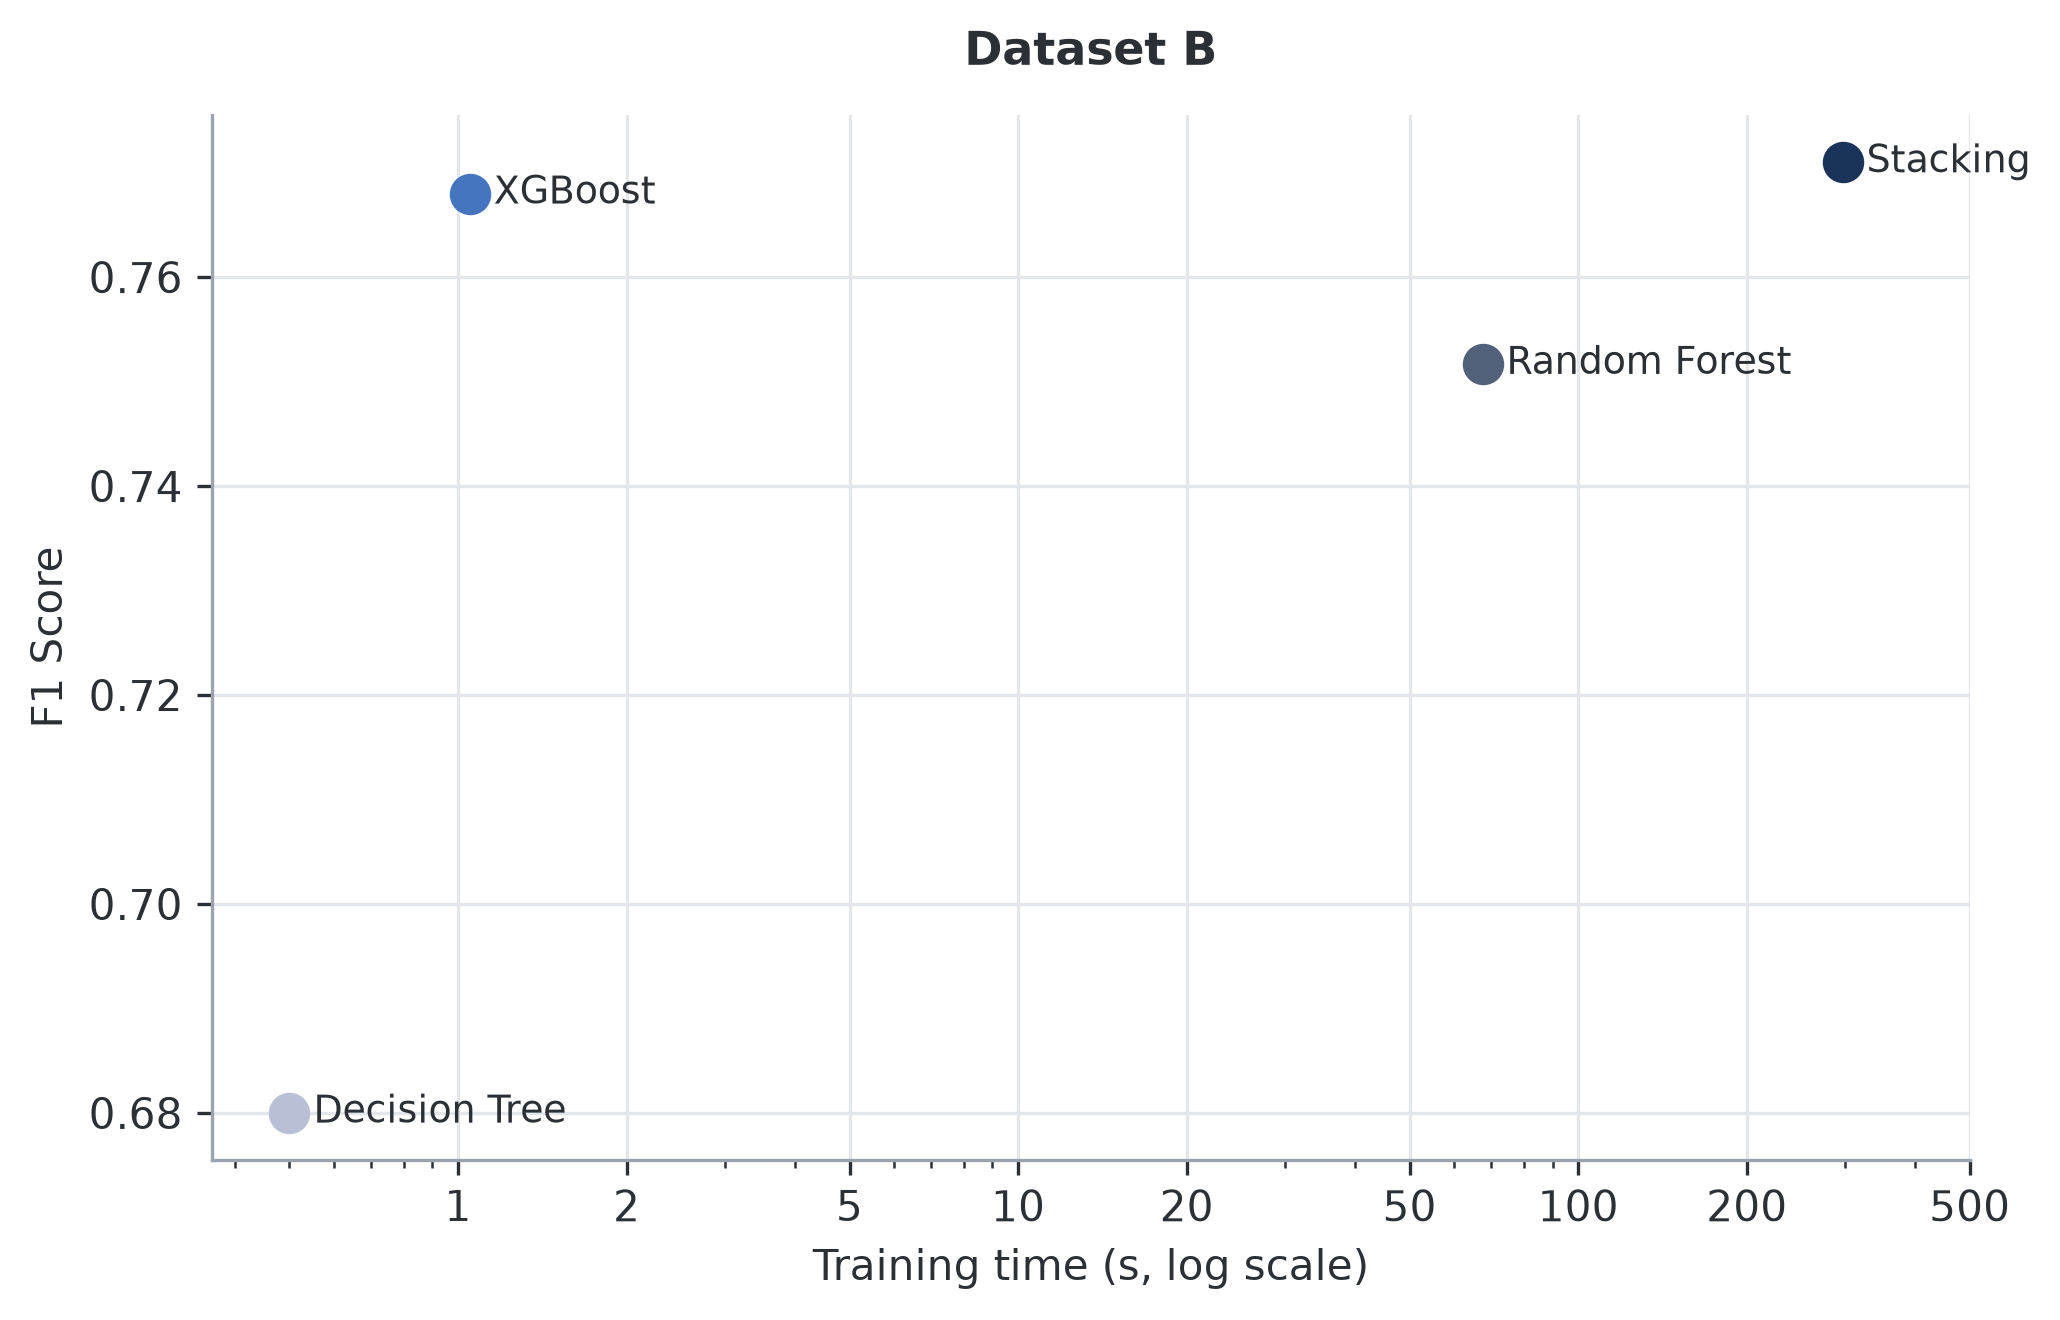

In [6]:
from matplotlib.ticker import ScalarFormatter, NullFormatter
plt.rcParams['figure.dpi'] = 300
ticks = {
    "A": [0.2, 0.5, 1, 2, 5, 10],
    "B": [1, 2, 5, 10, 20, 50, 100, 200, 500]
}

datasets = [("A", A), ("B", B)]

for name, d in datasets:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    
    # Loop model by model to assign custom colors and clean annotations
    for m in models:
        if m in d.index:
            x_val = d.loc[m, "train_time_s"]
            y_val = d.loc[m, "f1"]
            color = MODEL_COLORS.get(m, LIGHT_SLATE)
            label = MODEL_LABELS.get(m, m)
            
            ax.scatter(x_val, y_val, color=color, s=80, zorder=3)
            ax.annotate(f"  {label}", (x_val, y_val), fontsize=9, va="center")

    ax.set_xscale("log")
    ax.set_xticks(ticks[name])
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())     # hide cluttered minor labels
    
    ax.set_title(f"Dataset {name}")
    ax.set_xlabel("Training time (s, log scale)")
    ax.set_ylabel("F1 Score")
    
    plt.tight_layout()
    plt.show()

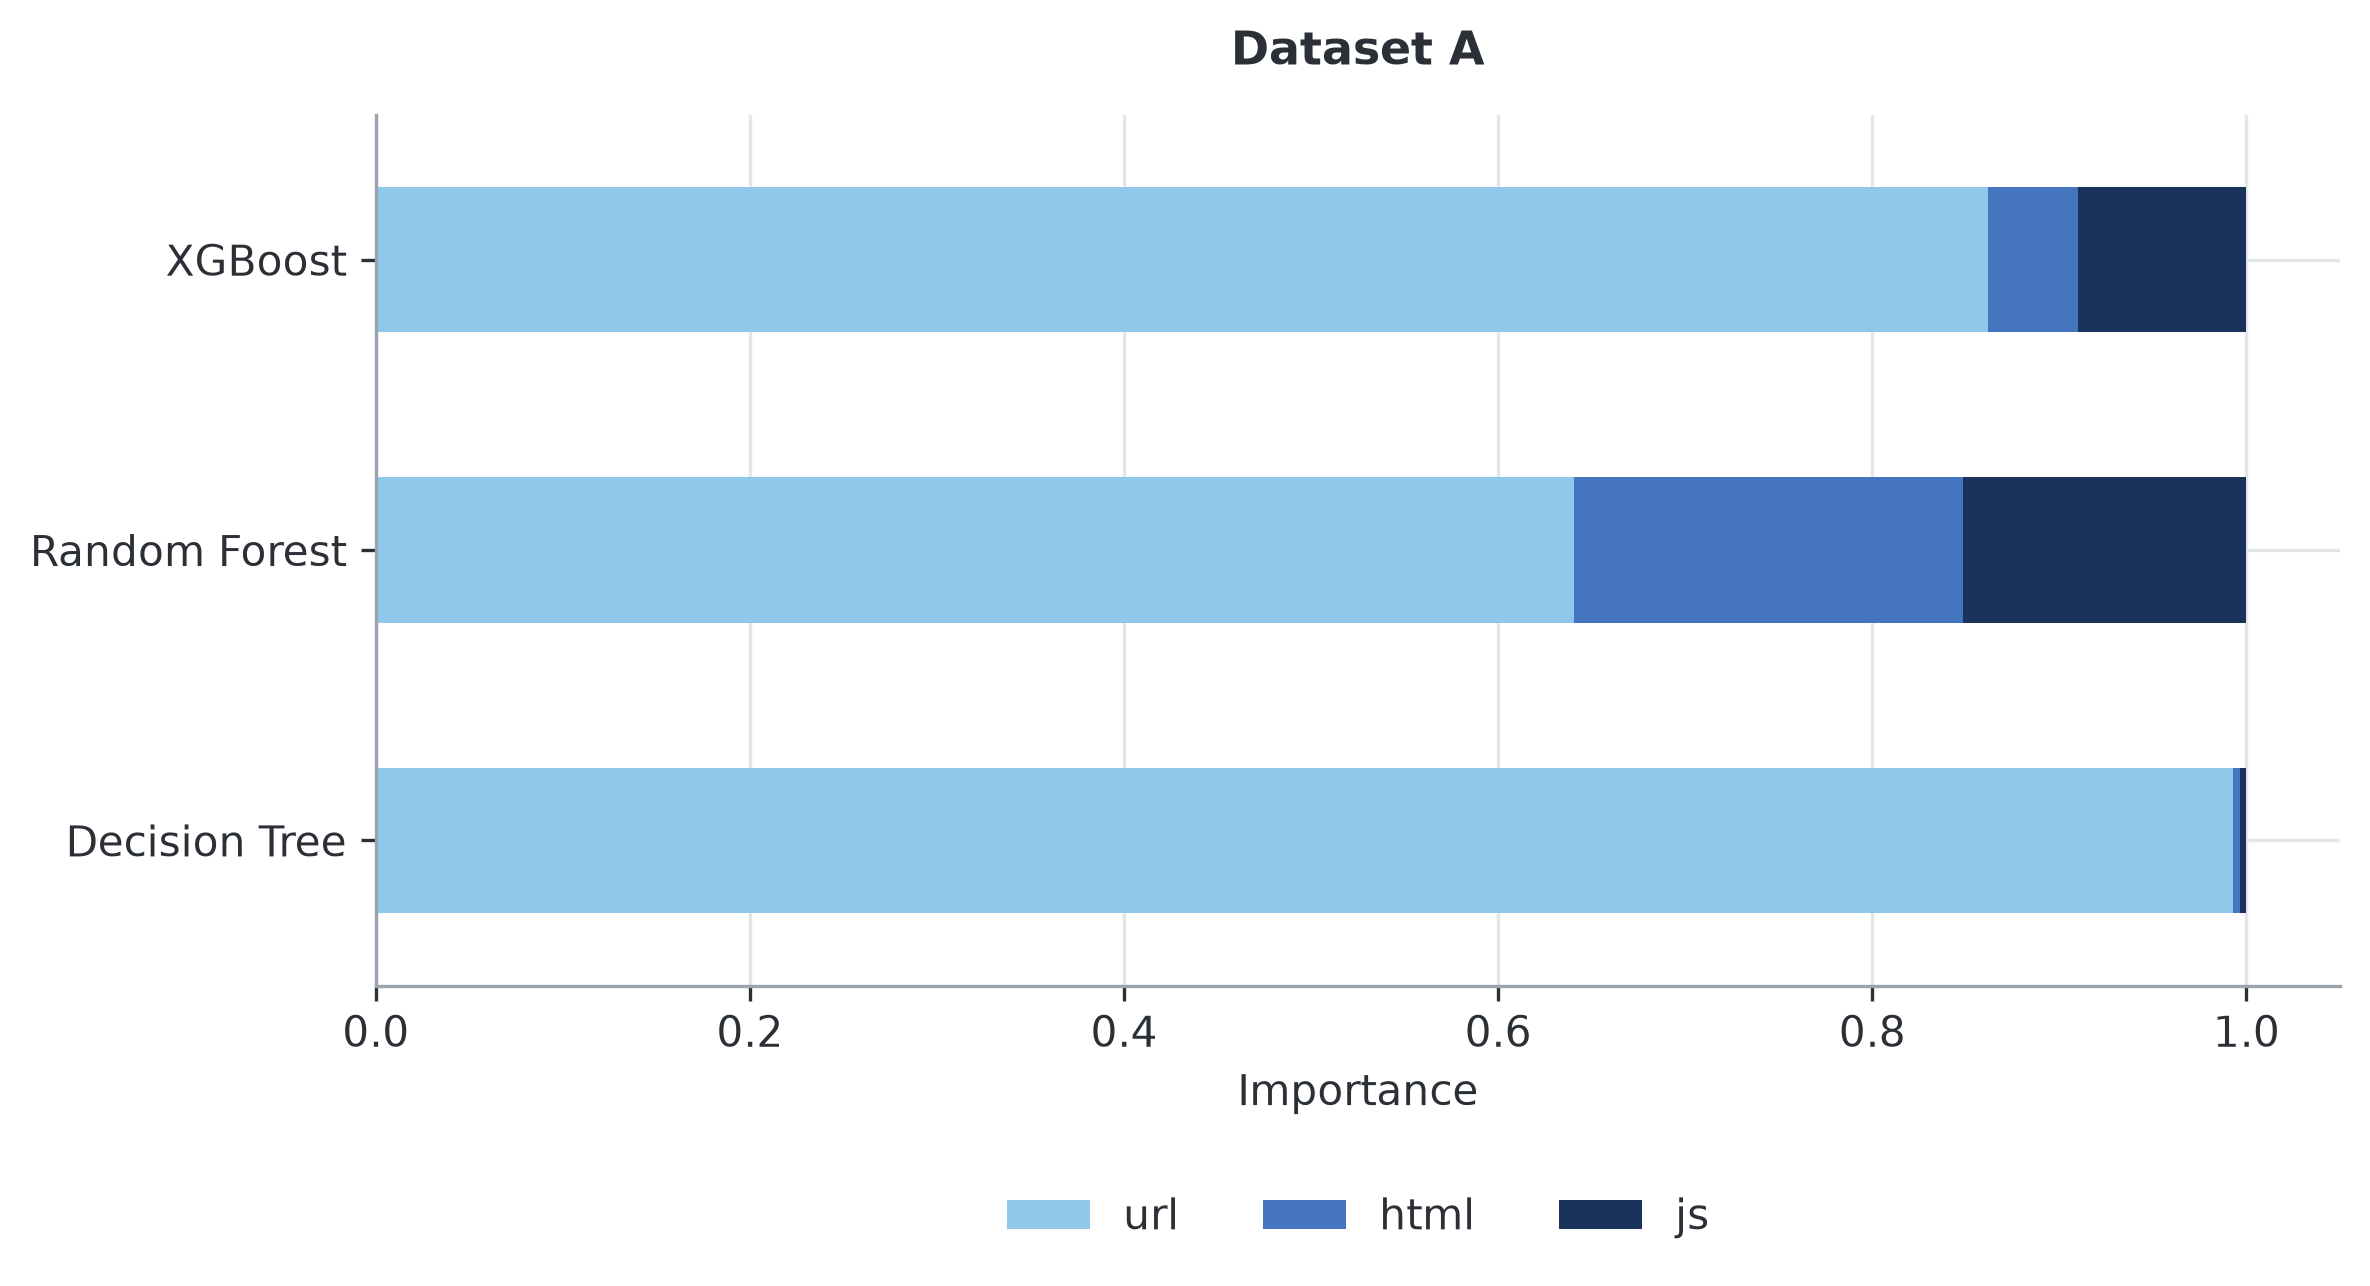

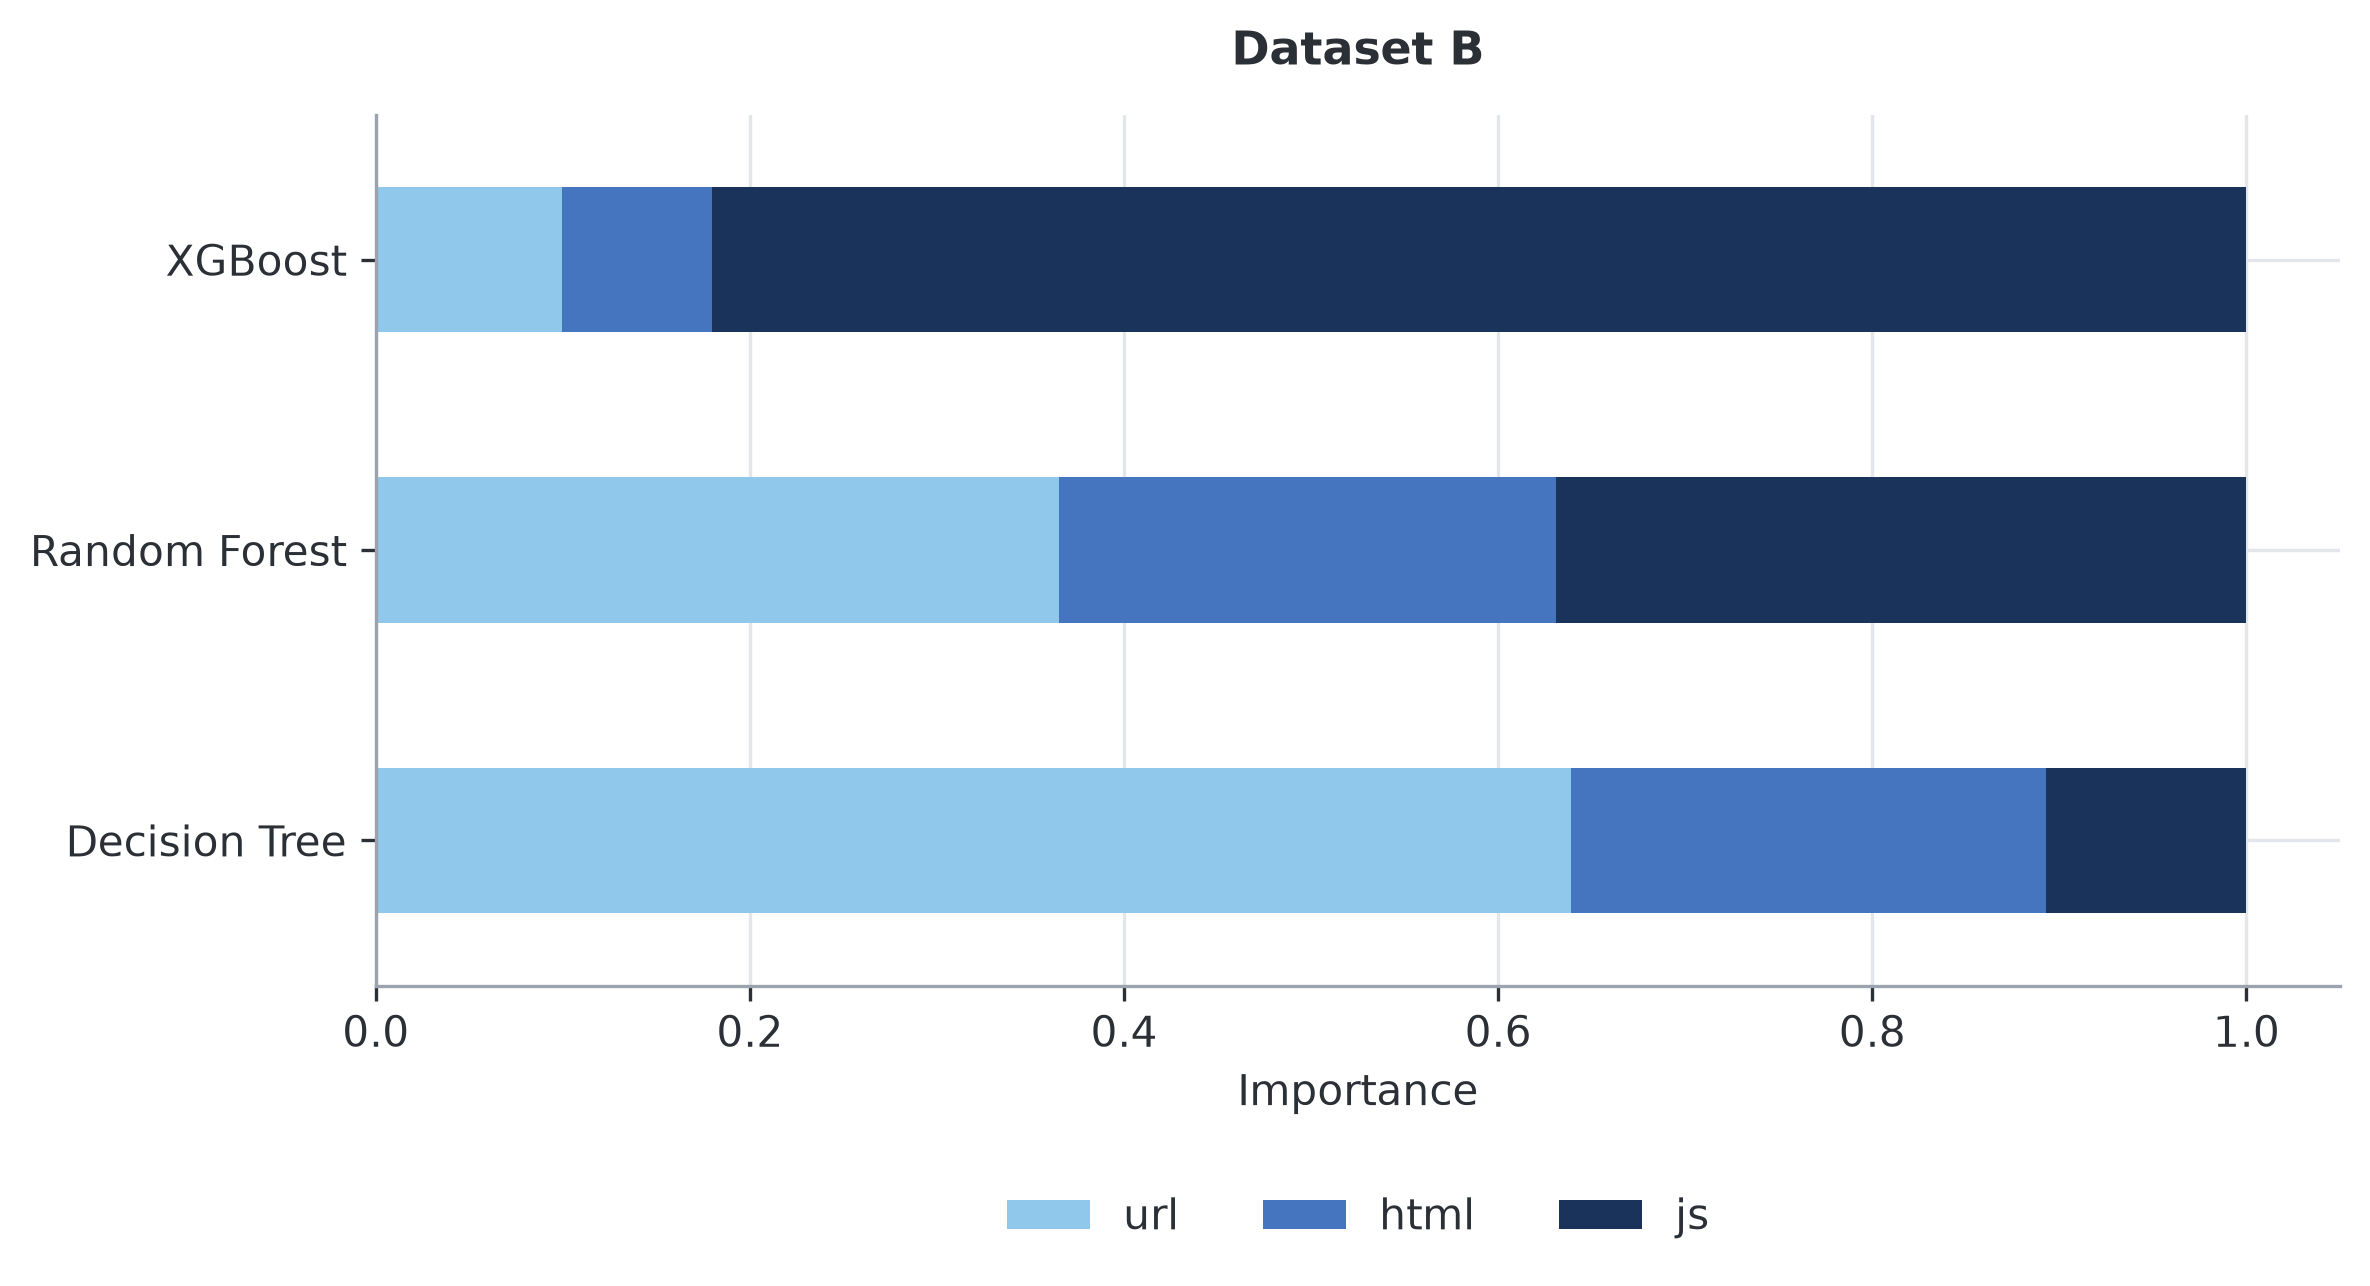

In [8]:
FEATURE_COLORS = [SKY_BLUE, ROYAL_BLUE, DEEP_NAVY]

datasets = [
    ("A", "results_final_E1/group_importance.csv"),
    ("B", "results_final_E2/group_importance.csv")
]

for name, path in datasets:
    # Slightly taller figure to comfortably fit the legend underneath
    fig, ax = plt.subplots(figsize=(8, 4.5))
    
    df = pd.read_csv(path).set_index("model")
    
    # Optional: filter by your `models` list if it exists in your environment
    if 'models' in globals():
        df = df.loc[df.index.intersection(models)]
        
    # Map raw model keys to clean display labels for the y-axis
    df.index = df.index.map(lambda x: MODEL_LABELS.get(x, x))
    
    # Plot stacked horizontal bar chart with custom colors
    df[["url", "html", "js"]].plot.barh(
        stacked=True, 
        ax=ax, 
        title=f"Dataset {name}",
        color=FEATURE_COLORS
    )
    
    ax.set_ylabel("")
    ax.set_xlabel("Importance")
    
    # Place the legend neatly underneath the plot area
    ax.legend(
        loc="upper center", 
        bbox_to_anchor=(0.5, -0.2), 
        ncol=3, 
        frameon=False
    )
    
    plt.tight_layout()
    plt.show()

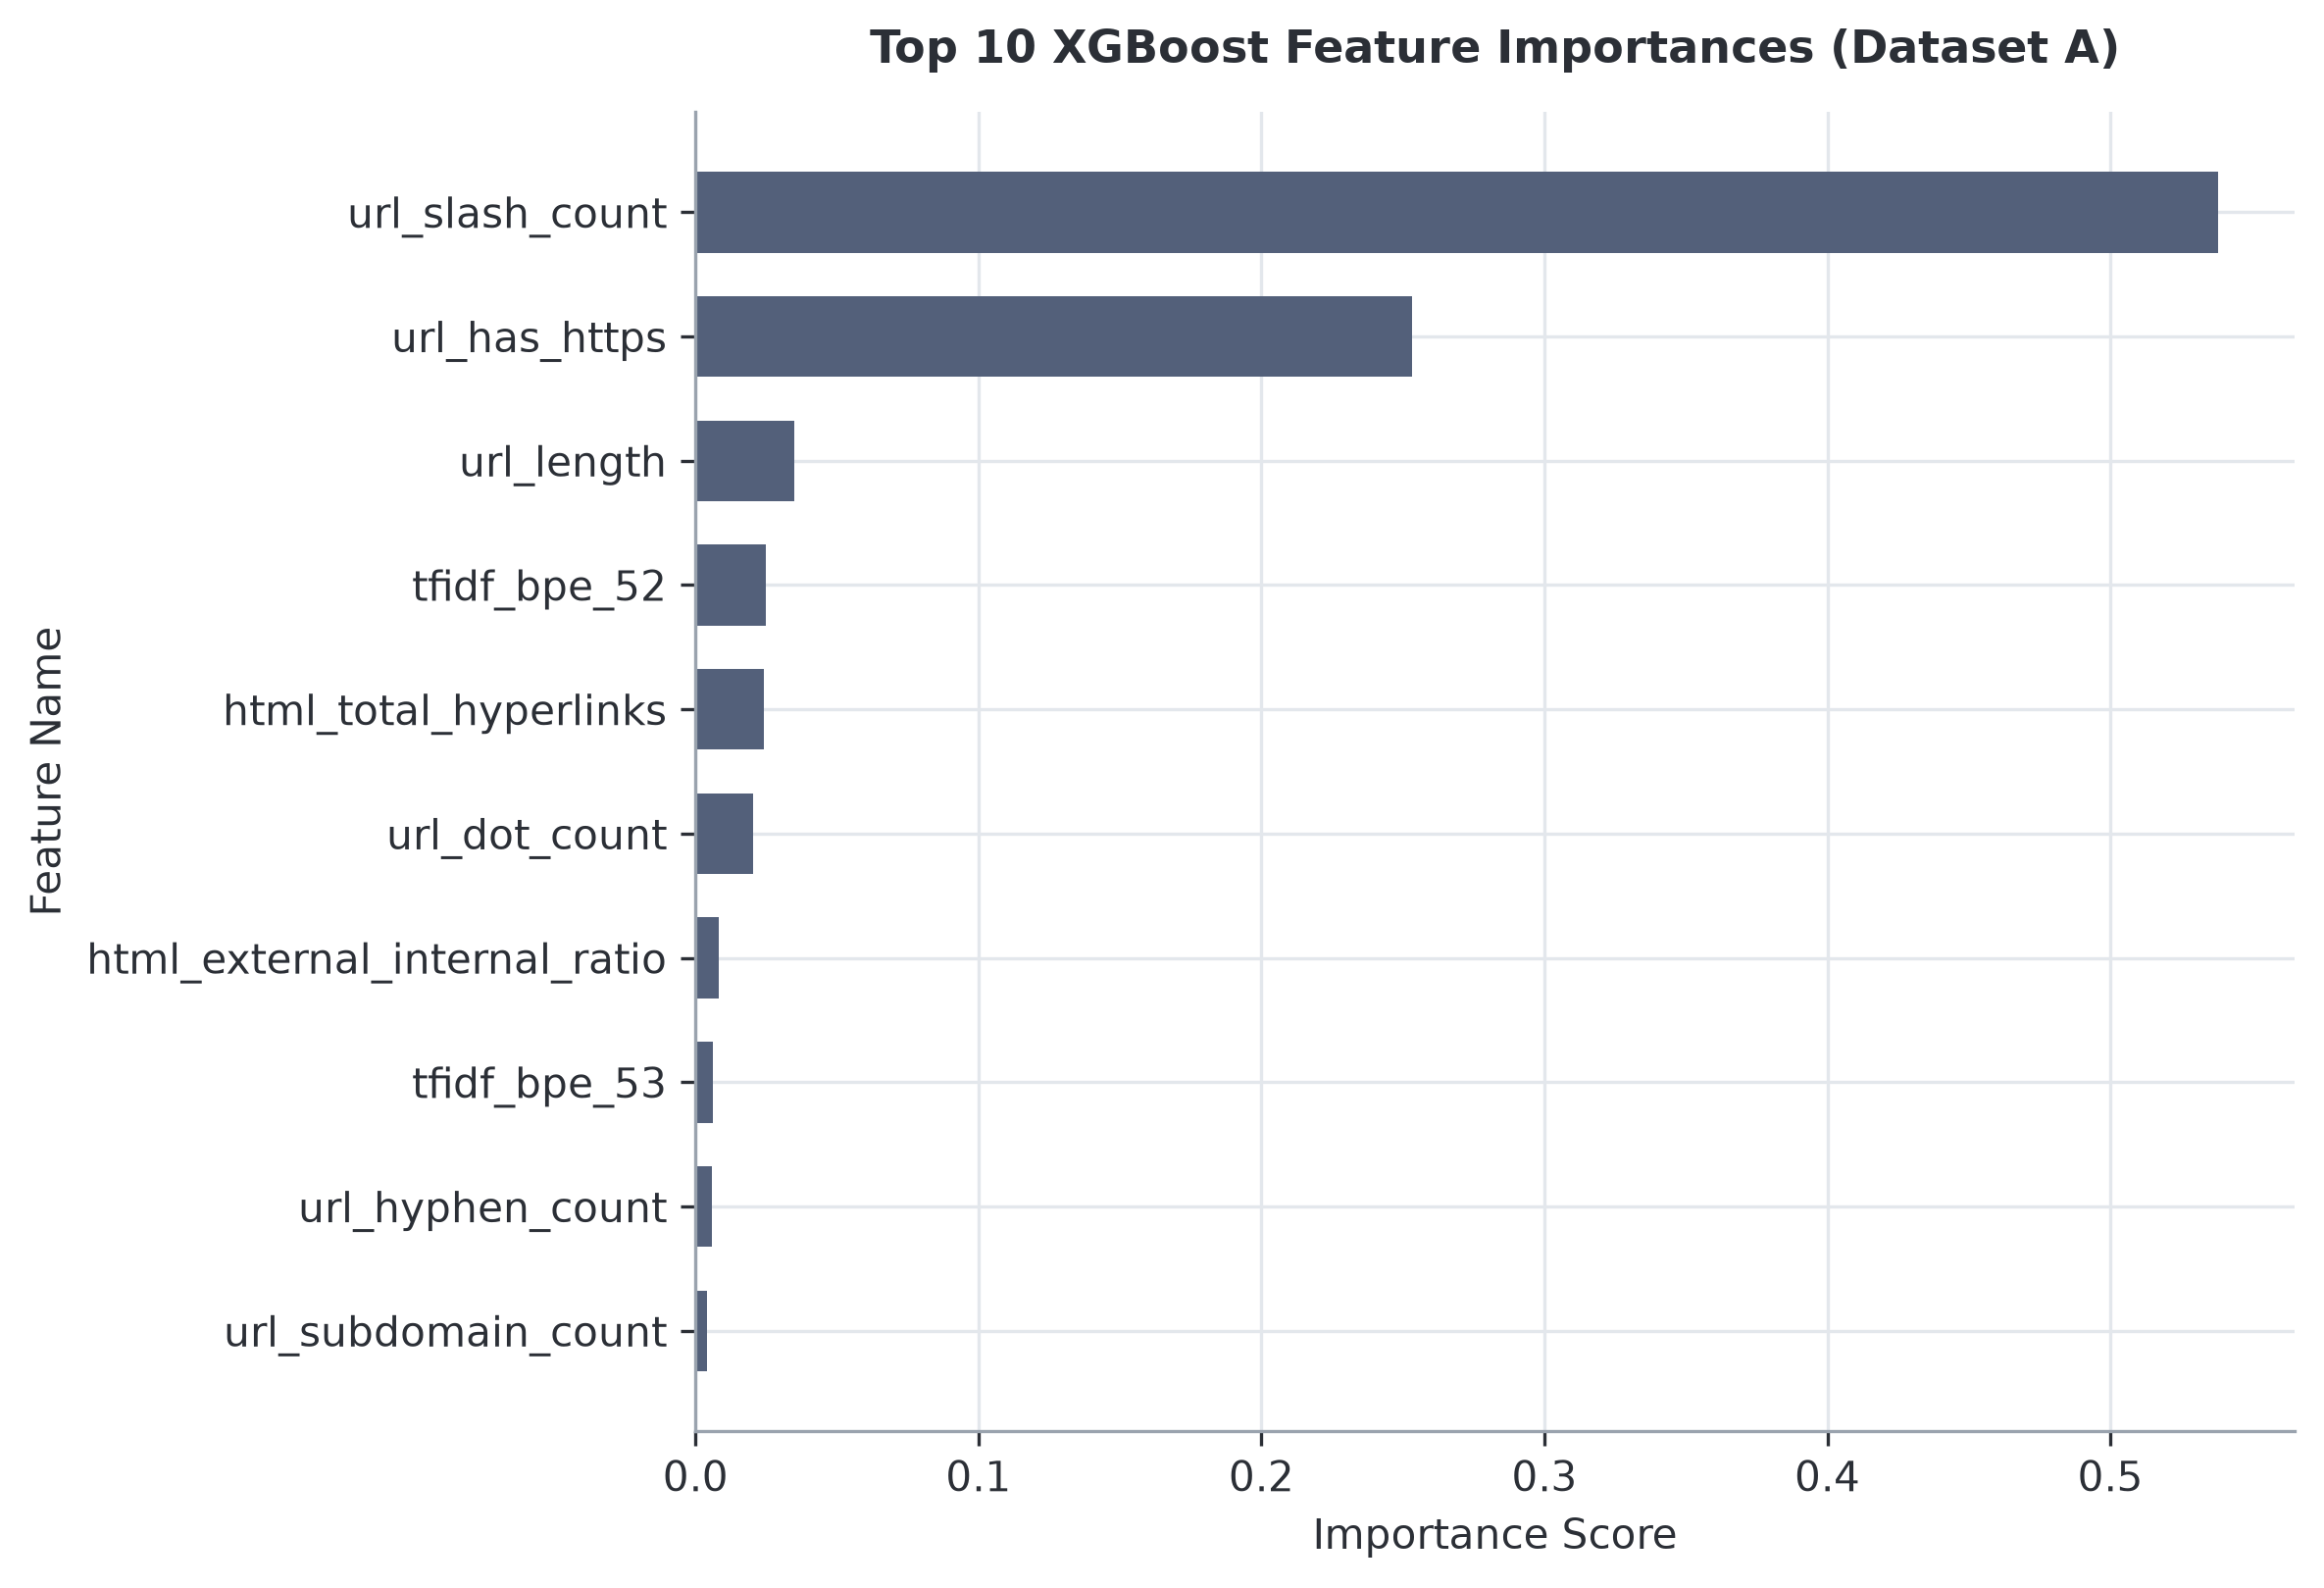

In [ ]:
features_data = {
    "url_slash_count": 0.5382,
    "url_has_https": 0.2532,
    "url_length": 0.0349,
    "tfidf_bpe_52": 0.0247,
    "html_total_hyperlinks": 0.0242,
    "url_dot_count": 0.0203,
    "html_external_internal_ratio": 0.0083,
    "tfidf_bpe_53": 0.0062,
    "url_hyphen_count": 0.0059,
    "url_subdomain_count": 0.0041,
}

plt.rcParams['figure.dpi'] = 300

# Convert to DataFrame and sort in ascending order for horizontal bar plot (bottom-to-top)
feature_importance = pd.DataFrame(
    list(features_data.items()), columns=["Feature", "Importance"]
).sort_values(by="Importance", ascending=True)

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(
    feature_importance["Feature"],
    feature_importance["Importance"],
    color=IID_SLATE,
    edgecolor="none",
    height=0.65,
)
ax.set_title("Top 10 XGBoost Feature Importances (Dataset A)")
ax.set_xlabel("Importance Score")
ax.set_ylabel("Feature Name")
plt.tight_layout()
plt.show()

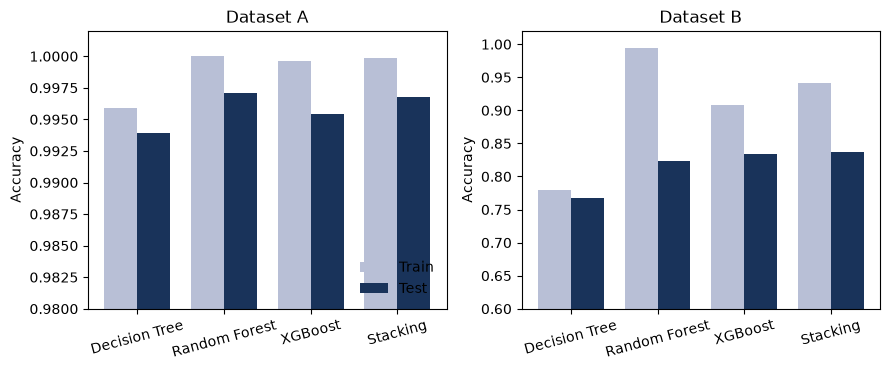

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=False)
for ax, (ds, path) in zip(axes, [("A", "results_final_E1/train_vs_test_A.csv"), ("B", "results_final_E2/train_vs_test_B.csv")]):
    d = pd.read_csv(path); x = np.arange(len(d)); w = 0.38
    ax.bar(x - w/2, d.train_acc, w, color="#B8BFD6", label="Train")
    ax.bar(x + w/2, d.test_acc, w, color="#19335A", label="Test")
    ax.set_xticks(x); ax.set_xticklabels(["Decision Tree", "Random Forest", "XGBoost", "Stacking"], rotation=15)
    ax.set_ylabel("Accuracy"); ax.set_title(f"Dataset {ds}")
    ax.set_ylim(0.98 if ds == "A" else 0.6, 1.002 if ds == "A" else 1.02)
axes[0].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig("fig_train_vs_test.png", dpi=300, bbox_inches="tight"); plt.show()